# PNW 2021 reproduction against Whittaker & Di Luca (2026)

Compares the EXP75 reproduction run on Nibi (job 22213902, 2026-09-18) with
the numbers the paper states for its EXP75 experiment, on the paper's own
measures. Runs on the laptop: it reads the CSVs `hpc/nibi/pull.sh` brought
home and needs no jax.

**Paper measures** (Sect. 2.1 and 3.2, Table 2):

- Peak 1000 hPa temperature of the optimized trajectory, box-averaged: 38.9 C.
- Peak anomaly of the optimized trajectory over the 75-member ensemble mean: 14.0 C.
- Maximum surface-pressure perturbation over the field: 0.47 Pa.
- Heat-wave intensity, Eq. 4: mean exceedance of the daily box-mean
  temperature above the 99th percentile of 6-hourly JJA values over
  1981-2020, over consecutive days above it. The headline **+3.7 C** is the
  optimized intensity minus the most extreme ensemble member's.
- Event length: 6 days for both optimized runs.

**Assumptions made here**, because the paper leaves them open:

- The threshold comes from ERA5, not from the 40-year NeuralGCM simulation
  the paper also shows (Fig. 1a); the paper notes the model's hot extremes
  are slightly colder than ERA5's, so an ERA5 threshold is slightly higher.
- ERA5 is read from WeatherBench2's 5.625 deg conservative regrid, which
  preserves area means, so the box mean is close to the 0.25 deg box mean.
- "Daily temperature" is the daily mean of the hourly box-mean series.
- Events are found over the full 11-day trajectory; intensity is reported
  both over the event days inside the targeted 5-day window (Jun 27 to
  Jul 1) and over the whole event.


In [31]:
from heatwave_ic.intensity import (box_mean_t1000_climatology, daily_mean,
                                   heatwave_events, intensity)
from common import mpl_apply
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "heatwave_ic").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
mpl_apply()

RUN = ROOT / "data/opt_runs/pnw_jun2021_i20210621_lr1em09_it75_lam10_b10_w1x100x100x10x10x1x1_d11"
story = pd.read_csv(RUN / "storyline.csv", index_col=0, parse_dates=True)
ens = pd.read_csv(RUN / "ensemble.csv", index_col=0, parse_dates=True)
ens_mean = ens.mean(axis=1)
# the last 5 days: the loss window
WINDOW = slice("2021-06-27", "2021-07-01")
print(f"{ens.shape[1]} members, {len(story)} hourly steps "
      f"{story.index[0]} to {story.index[-1]}")

75 members, 264 hourly steps 2021-06-21 00:00:00 to 2021-07-01 23:00:00


## Peak, anomaly over the ensemble mean, perturbation size

The quantities the paper states in Sect. 3.2 and Table 2.

In [32]:
opt, ctrl = story["optimized_C"], story["unperturbed_C"]
sp_opt = np.load(RUN / "log_surface_pressure_opt.npy")
sp_ori = np.load(RUN / "log_surface_pressure_original.npy")
ours = {
    "optimized peak T1000 (C)": opt.max(),
    "control peak T1000 (C)": ctrl.max(),
    "hottest member peak T1000 (C)": ens.max().max(),
    "peak anomaly over ensemble mean (C)": (opt - ens_mean).max(),
    "max surface-pressure perturbation (Pa)": np.abs(sp_opt - sp_ori).max(),
    "5-day window mean, optimized minus hottest member (C)":
        opt.loc[WINDOW].mean() - ens.loc[WINDOW].mean().max(),
}
pd.Series(ours).round(2)

optimized peak T1000 (C)                                 38.62
control peak T1000 (C)                                   32.65
hottest member peak T1000 (C)                            36.70
peak anomaly over ensemble mean (C)                      13.94
max surface-pressure perturbation (Pa)                    0.20
5-day window mean, optimized minus hottest member (C)     3.43
dtype: float64

## The 99th-percentile threshold

6-hourly JJA box-mean T1000 over 1981-2020. The first call downloads about
1.6 GB and caches the series in `data/`; later calls read the cache.

In [33]:
clim = box_mean_t1000_climatology()
P95, P99 = clim.quantile(0.95), clim.quantile(0.99)
print(f"{len(clim)} values; p95 = {P95:.2f} C, p99 = {P99:.2f} C, max = {clim.max():.2f} C")

  1981: 368 snapshots
  1982: 368 snapshots
  1983: 368 snapshots
  1984: 368 snapshots
  1985: 368 snapshots
  1986: 368 snapshots
  1987: 368 snapshots
  1988: 368 snapshots
  1989: 368 snapshots
  1990: 368 snapshots
  1991: 368 snapshots
  1992: 368 snapshots
  1993: 368 snapshots
  1994: 368 snapshots
  1995: 368 snapshots
  1996: 368 snapshots
  1997: 368 snapshots
  1998: 368 snapshots
  1999: 368 snapshots
  2000: 368 snapshots
  2001: 368 snapshots
  2002: 368 snapshots
  2003: 368 snapshots
  2004: 368 snapshots
  2005: 368 snapshots
  2006: 368 snapshots
  2007: 368 snapshots
  2008: 368 snapshots
  2009: 368 snapshots
  2010: 368 snapshots
  2011: 368 snapshots
  2012: 368 snapshots
  2013: 368 snapshots
  2014: 368 snapshots
  2015: 368 snapshots
  2016: 368 snapshots
  2017: 368 snapshots
  2018: 368 snapshots
  2019: 368 snapshots
  2020: 368 snapshots
14720 values; p95 = 27.65 C, p99 = 30.21 C, max = 34.25 C


## Intensity (Eq. 4) and event length

In [34]:
def eq4(hourly):
    d = daily_mean(hourly)
    # longest event, whole trajectory
    full = intensity(d, P99)
    # the event's days inside the window
    in_win = intensity(d.loc[WINDOW], P99)
    return {"length_d": full["length_d"],
            "intensity_full_C": full["intensity_C"],
            "intensity_window_C": in_win["intensity_C"],
            "days_above_p99_in_window": int((d.loc[WINDOW] > P99).sum())}


members = pd.DataFrame({m: eq4(ens[m]) for m in ens}).T
rows = pd.DataFrame({"optimized": eq4(opt), "control": eq4(ctrl),
                     "hottest member (by intensity)": members.loc[members.intensity_window_C.idxmax()],
                     "ensemble mean of members": members.mean()}).T
rows.round(2)

,length_d,intensity_full_C,intensity_window_C,days_above_p99_in_window
optimized,6.00,2.82,3.25,5.00
control,0.00,0.00,0.00,0.00
hottest member (by intensity),2.00,2.03,2.03,2.00
ensemble mean of members,0.33,0.18,0.18,0.33


In [35]:
gain_window = rows.loc["optimized",
                       "intensity_window_C"] - members.intensity_window_C.max()
gain_full = rows.loc["optimized", "intensity_full_C"] - \
    members.intensity_full_C.max()
print(f"gain over the most extreme member, Eq. 4 intensity: "
      f"{gain_window:+.2f} C inside the 5-day window, {gain_full:+.2f} C over the whole event")
print(
    f"members with any day above p99: {(members.days_above_p99_in_window > 0).sum()} of {len(members)}")

gain over the most extreme member, Eq. 4 intensity: +1.22 C inside the 5-day window, +0.79 C over the whole event
members with any day above p99: 14 of 75


## Side by side with the paper

In [36]:
paper = {
    "optimized peak T1000 (C)": 38.9,
    "peak anomaly over ensemble mean (C)": 14.0,
    "max surface-pressure perturbation (Pa)": 0.47,
    "intensity gain over most extreme member, Eq. 4 (C)": 3.7,
    "optimized event length (d)": 6,
}
mine = {
    "optimized peak T1000 (C)": ours["optimized peak T1000 (C)"],
    "peak anomaly over ensemble mean (C)": ours["peak anomaly over ensemble mean (C)"],
    "max surface-pressure perturbation (Pa)": ours["max surface-pressure perturbation (Pa)"],
    "intensity gain over most extreme member, Eq. 4 (C)": gain_window,
    "optimized event length (d)": rows.loc["optimized", "length_d"],
}
table = pd.DataFrame({"paper EXP75": paper, "this run": mine})
table["difference"] = table["this run"] - table["paper EXP75"]
table = table.round(2)
table.to_csv(ROOT / "data/pnw_jun2021_vs_paper.csv")
table

,paper EXP75,this run,difference
optimized peak T1000 (C),38.90,38.62,-0.28
peak anomaly over ensemble mean (C),14.00,13.94,-0.06
max surface-pressure perturbation (Pa),0.47,0.20,-0.27
"intensity gain over most extreme member, Eq. 4 (C)",3.70,1.22,-2.48
optimized event length (d),6.00,6.00,0.00


## Figure

Hourly box-mean T1000 for every member (grey), the ensemble mean (black),
the control (blue) and the optimized run (red), with the p99 threshold and
the targeted window; and the distribution of member intensities against the
optimized run.

Plot -> /Users/isaacadoboe/Developer/heatwave-initial-conditions/plots/atlas/pnw_jun2021_vs_paper.pdf


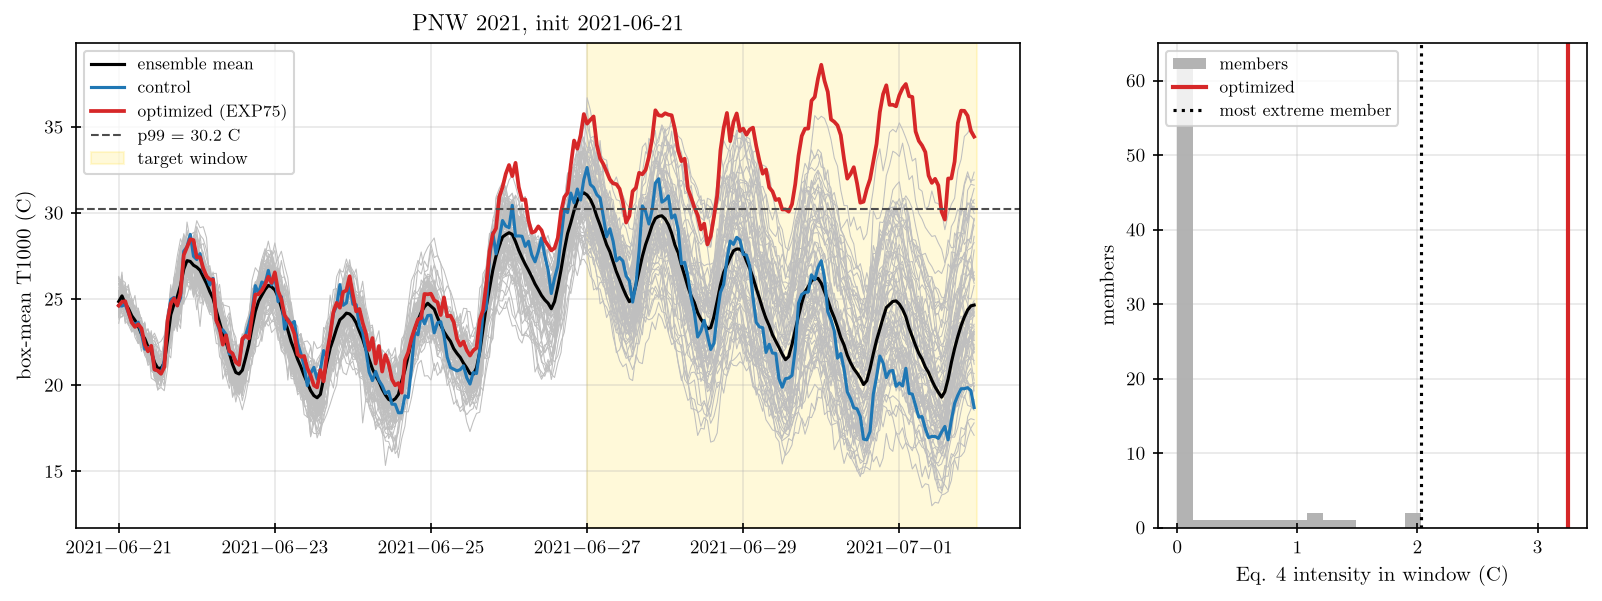

In [37]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2),
                           gridspec_kw={"width_ratios": [2.2, 1]})
a.plot(ens.index, ens.values, color="0.75", lw=0.5)
a.plot(ens_mean.index, ens_mean.values,
       color="k", lw=1.5, label="ensemble mean")
a.plot(ctrl.index, ctrl.values, color="tab:blue", lw=1.5, label="control")
a.plot(opt.index, opt.values, color="tab:red",
       lw=1.8, label="optimized (EXP75)")
a.axhline(P99, ls="--", color="0.3", lw=1, label=f"p99 = {P99:.1f} C")
a.axvspan(pd.Timestamp("2021-06-27"), pd.Timestamp("2021-07-02"),
          color="gold", alpha=0.15, label="target window")
a.set(ylabel="box-mean T1000 (C)", title="PNW 2021, init 2021-06-21")
a.legend(loc="upper left", fontsize=8)
a.grid(alpha=0.3)
b.hist(members.intensity_window_C, bins=15, color="0.7", label="members")
b.axvline(rows.loc["optimized", "intensity_window_C"],
          color="tab:red", lw=2, label="optimized")
b.axvline(members.intensity_window_C.max(), color="k",
          ls=":", lw=1.5, label="most extreme member")
b.set(xlabel="Eq. 4 intensity in window (C)", ylabel="members")
b.legend(fontsize=8)
b.grid(alpha=0.3)
out = ROOT / "plots/atlas/pnw_jun2021_vs_paper.pdf"
fig.savefig(out, bbox_inches="tight")
print("Plot ->", out)

## How to read the table

- The storyline itself reproduces: peak and anomaly over the ensemble mean
  land within a few tenths of a degree of the paper.
- The Eq. 4 comparison is the like-for-like one. Its remaining gap to the
  paper has two known contributors: the regularization reference scale
  (`heatwave_ic/optimize.py` docstring), which makes the perturbation
  smaller than the paper's (see the surface-pressure row), and the
  threshold source (ERA5 here, possibly NeuralGCM in the paper).
- ??? The loss was still falling at iteration 75 (`losses.npy`), as the paper's
  own EXP50-to-EXP75 step of +1.0 C in intensity also implies.
